# Projet 1 — Réseaux de Neurones Artificiels (ANN) : Classification du cancer du sein
### ANN optimisé par la méthode de Taguchi — jeu de données Wisconsin Diagnostic Breast Cancer (WDBC)

**Article de référence :** *Artificial Neural Network with Taguchi Method for Robust Classification Model to Improve Classification Accuracy of Breast Cancer* (PeerJ Computer Science, 2021) — https://pmc.ncbi.nlm.nih.gov/articles/PMC7924699/

**Données :** UCI — Breast Cancer Wisconsin (Diagnostic) — https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
569 observations, 30 variables explicatives (caractéristiques des noyaux cellulaires), 2 classes : **bénin (B)** et **malin (M)**.

#### Plan du notebook
1. Chargement et exploration des données
2. Prétraitement (encodage, partition, normalisation)
3. Modèle ANN (perceptron multicouche, arrêt précoce sur la validation)
4. **Méthode de Taguchi — Expérience 1** : réglage des hyperparamètres avec un tableau orthogonal L9(3⁴), rapport signal/bruit (S/N), effets principaux, ANOVA, expérience de confirmation
5. **Méthode de Taguchi — Expérience 2** : choix de la partition des données (50/25/25, 60/20/20, 70/15/15, 80/10/10)
6. Évaluation finale : 30 exécutions aléatoires + validation croisée 10-fold (accuracy, sensibilité, spécificité, F-score, AUC)
7. Comparaison avec d'autres classifieurs et avec l'article
8. Conclusion

## 0. Imports et configuration

In [1]:
import os, copy, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, roc_auc_score,
                             roc_curve, classification_report, log_loss)
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

SEED = 42
np.random.seed(SEED)
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
print("OK")

OK


## 1. Chargement et exploration des données

In [2]:
DATA_PATH = "data/wdbc.csv"
if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
else:
    # Secours : fichier brut UCI (id, diagnostic, 30 variables, sans en-tête)
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"
    base = ["radius", "texture", "perimeter", "area", "smoothness", "compactness",
            "concavity", "concave points", "symmetry", "fractal dimension"]
    cols = ["id", "diagnosis"] + [f"mean {b}" for b in base] + [f"{b} error" for b in base] + [f"worst {b}" for b in base]
    df = pd.read_csv(url, header=None, names=cols).drop(columns="id")

print("Dimensions :", df.shape)
df.head()

Dimensions : (569, 31)


,diagnosis,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
print("Valeurs manquantes :", int(df.isna().sum().sum()))
print("\nRépartition des classes :")
print(df["diagnosis"].value_counts().rename({"B": "Bénin (B)", "M": "Malin (M)"}))
df.describe().T.head(10)

Valeurs manquantes : 0

Répartition des classes :
diagnosis
Bénin (B)    357
Malin (M)    212
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


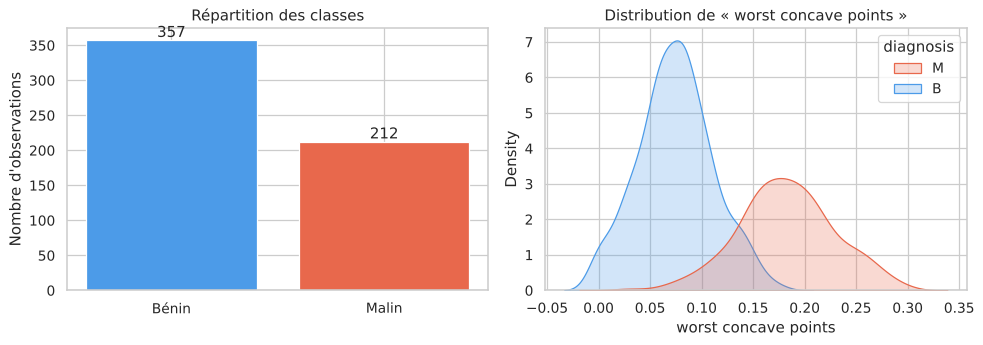

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
counts = df["diagnosis"].value_counts()
axes[0].bar(["Bénin", "Malin"], [counts["B"], counts["M"]], color=["#4C9BE8", "#E8684C"])
for i, v in enumerate([counts["B"], counts["M"]]):
    axes[0].text(i, v + 5, str(v), ha="center")
axes[0].set_title("Répartition des classes")
axes[0].set_ylabel("Nombre d'observations")

sns.kdeplot(data=df, x="worst concave points", hue="diagnosis", fill=True, ax=axes[1],
            palette={"B": "#4C9BE8", "M": "#E8684C"})
axes[1].set_title("Distribution de « worst concave points »")
plt.tight_layout(); plt.savefig("figures/01_classes.png", bbox_inches="tight"); plt.show()

10 variables les plus corrélées au diagnostic (|r|) :
worst concave points    0.794
worst perimeter         0.783
mean concave points     0.777
worst radius            0.776
mean perimeter          0.743
worst area              0.734
mean radius             0.730
mean area               0.709
mean concavity          0.696
worst concavity         0.660
dtype: float64


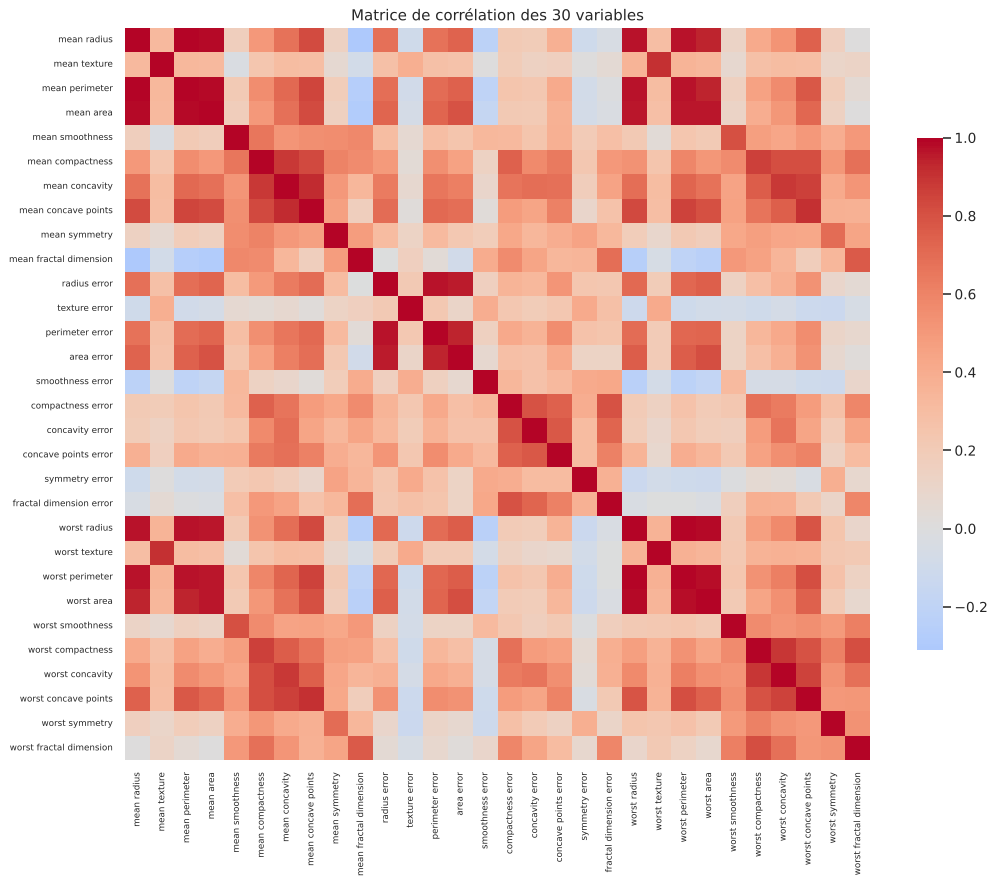

In [5]:
X_all = df.drop(columns="diagnosis")
corr = X_all.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, xticklabels=True, yticklabels=True, cbar_kws={"shrink": .7})
plt.title("Matrice de corrélation des 30 variables")
plt.xticks(fontsize=7); plt.yticks(fontsize=7)
plt.tight_layout(); plt.savefig("figures/02_correlation.png", bbox_inches="tight"); plt.show()

y_tmp = (df["diagnosis"] == "M").astype(int)
top = X_all.corrwith(y_tmp).abs().sort_values(ascending=False).head(10)
print("10 variables les plus corrélées au diagnostic (|r|) :")
print(top.round(3))

## 2. Prétraitement
- Encodage de la cible : **Malin = 1 (classe positive)**, Bénin = 0.
- Partition stratifiée **entraînement / validation / test** (la validation sert à l'arrêt précoce et à la sélection Taguchi ; le test n'est utilisé qu'à la fin).
- Normalisation `StandardScaler` **ajustée uniquement sur l'entraînement** (pas de fuite d'information).

In [6]:
X = df.drop(columns="diagnosis").values.astype(float)
y = (df["diagnosis"] == "M").astype(int).values
feature_names = df.drop(columns="diagnosis").columns.tolist()

def split_data(X, y, train=0.70, val=0.15, test=0.15, seed=SEED):
    # Partition stratifiée train/val/test + normalisation ajustée sur train
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, train_size=train, stratify=y, random_state=seed)
    rel_test = test / (val + test)
    X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=rel_test, stratify=y_tmp, random_state=seed)
    sc = StandardScaler().fit(X_tr)
    return sc.transform(X_tr), sc.transform(X_va), sc.transform(X_te), y_tr, y_va, y_te

X_tr, X_va, X_te, y_tr, y_va, y_te = split_data(X, y)
print(f"Entraînement : {X_tr.shape[0]} | Validation : {X_va.shape[0]} | Test : {X_te.shape[0]}")

Entraînement : 398 | Validation : 85 | Test : 86


## 3. Modèle ANN
Comme dans l'article : réseau *feed-forward* à **une couche cachée**, 30 entrées, sortie probabiliste (softmax/sigmoïde), fonction de coût **entropie croisée**, entraînement par descente de gradient, **arrêt précoce** sur l'erreur de validation (on conserve les meilleurs poids).

La fonction `train_ann` entraîne époque par époque (`partial_fit`) pour suivre les courbes d'apprentissage.

In [7]:
def train_ann(X_tr, y_tr, X_va, y_va, hidden=15, lr=0.01, activation="logistic", alpha=1e-4, batch=32,
              seed=SEED, max_epochs=300, patience=25, return_history=False):
    clf = MLPClassifier(hidden_layer_sizes=(hidden,), activation=activation, solver="adam",
                        learning_rate_init=lr, batch_size=batch, alpha=alpha,
                        max_iter=1, warm_start=True, random_state=seed)
    classes = np.array([0, 1])
    best_loss, best_model, wait = np.inf, None, 0
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(max_epochs):
        clf.partial_fit(X_tr, y_tr, classes=classes)
        p_va = clf.predict_proba(X_va)[:, 1]
        vl = log_loss(y_va, p_va, labels=[0, 1])
        if return_history:
            p_tr = clf.predict_proba(X_tr)[:, 1]
            hist["train_loss"].append(log_loss(y_tr, p_tr, labels=[0, 1]))
            hist["val_loss"].append(vl)
            hist["train_acc"].append(accuracy_score(y_tr, (p_tr >= .5).astype(int)))
            hist["val_acc"].append(accuracy_score(y_va, (p_va >= .5).astype(int)))
        if vl < best_loss - 1e-5:
            best_loss, best_model, wait, best_epoch = vl, copy.deepcopy(clf), 0, epoch + 1
        else:
            wait += 1
            if wait >= patience:
                break
    best_model.best_epoch_ = best_epoch
    return (best_model, hist) if return_history else best_model

def metrics(model, X_, y_):
    proba = model.predict_proba(X_)[:, 1]
    pred = (proba >= .5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_, pred, labels=[0, 1]).ravel()
    return {"accuracy": (tp + tn) / len(y_),
            "sensitivity": tp / (tp + fn),       # rappel classe maligne
            "specificity": tn / (tn + fp),
            "precision": tp / (tp + fp) if tp + fp else 0.0,
            "f1": f1_score(y_, pred),
            "auc": roc_auc_score(y_, proba)}

def train_with(p, X_tr, y_tr, X_va, y_va, seed=SEED, **kw):
    # Entraîne un ANN avec un dictionnaire de paramètres Taguchi
    return train_ann(X_tr, y_tr, X_va, y_va, hidden=p["A_neurones"], lr=p["B_lr"],
                     activation=p["C_activation"], alpha=p["D_alpha"], seed=seed, **kw)

# Modèle de départ (configuration de l'article : 15 neurones cachés, sigmoïde)
t0 = time.time()
base_model, base_hist = train_ann(X_tr, y_tr, X_va, y_va, hidden=15, lr=0.01, activation="logistic",
                                  batch=32, return_history=True)
print(f"Meilleure époque : {base_model.best_epoch_}  ({time.time()-t0:.1f}s)")
print("Validation :", {k: round(float(v), 4) for k, v in metrics(base_model, X_va, y_va).items()})

Meilleure époque : 12  (0.3s)
Validation : {'accuracy': 0.9765, 'sensitivity': 0.9375, 'specificity': 1.0, 'precision': 1.0, 'f1': 0.9677, 'auc': 0.9965}


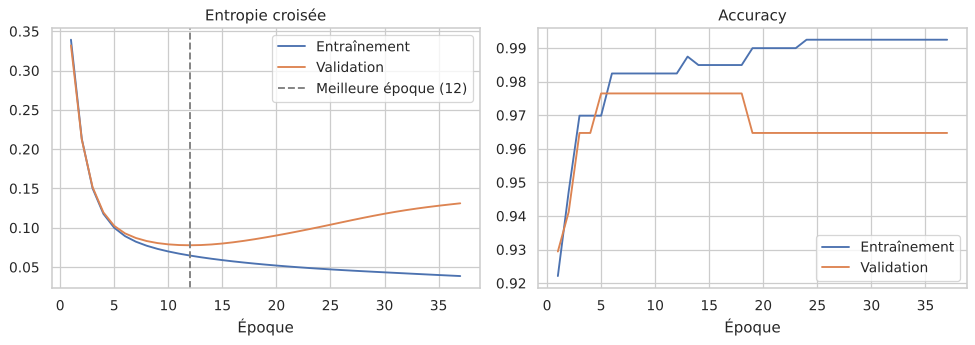

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ep = np.arange(1, len(base_hist["train_loss"]) + 1)
ax[0].plot(ep, base_hist["train_loss"], label="Entraînement")
ax[0].plot(ep, base_hist["val_loss"], label="Validation")
ax[0].axvline(base_model.best_epoch_, ls="--", c="gray", label=f"Meilleure époque ({base_model.best_epoch_})")
ax[0].set_title("Entropie croisée"); ax[0].set_xlabel("Époque"); ax[0].legend()
ax[1].plot(ep, base_hist["train_acc"], label="Entraînement")
ax[1].plot(ep, base_hist["val_acc"], label="Validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Époque"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/03_courbes_apprentissage.png", bbox_inches="tight"); plt.show()

## 4. Méthode de Taguchi — Expérience 1 : hyperparamètres de l'ANN

La méthode de Taguchi remplace le plan factoriel complet (ici 3⁴ = 81 combinaisons) par un **tableau orthogonal** : avec **L9(3⁴)**, 9 essais suffisent pour estimer l'effet principal de 4 facteurs à 3 niveaux, chaque niveau d'un facteur apparaissant le même nombre de fois avec chaque niveau des autres facteurs.

| Facteur | Niveau 1 | Niveau 2 | Niveau 3 |
|---|---|---|---|
| A — Neurones cachés | 10 | 15 | 20 |
| B — Taux d'apprentissage (Adam) | 0,001 | 0,01 | 0,05 |
| C — Fonction d'activation | logistic (sigmoïde) | tanh | relu |
| D — Régularisation L2 (alpha) | 0,0001 | 0,01 | 0,1 |

L'article fait varier les neurones cachés entre 10 et 20 ; nous ajoutons trois facteurs usuels pour rendre l'étude plus complète (taille de lot fixée à 32).

**Réponse et robustesse :** l'ensemble de **test (15 %) est mis de côté** et n'intervient jamais dans le réglage. Sur les 85 % restants (« développement »), chaque essai est évalué par **validation croisée stratifiée 5-fold répétée 3 fois** (graines différentes = facteurs de bruit), soit **n = 15 mesures d'accuracy** par essai (chaque fold : ~97 observations, avec 15 % du fold d'entraînement réservés à l'arrêt précoce). On calcule le **rapport S/N « plus c'est grand, mieux c'est »** :

$$ S/N = -10\,\log_{10}\left(\frac{1}{n}\sum_{i=1}^{n}\frac{1}{y_i^2}\right) $$

Un S/N élevé signifie une accuracy à la fois **élevée et stable**.

In [9]:
L9 = np.array([[1,1,1,1],[1,2,2,2],[1,3,3,3],
               [2,1,2,3],[2,2,3,1],[2,3,1,2],
               [3,1,3,2],[3,2,1,3],[3,3,2,1]])
levels = {"A_neurones": [10, 15, 20],
          "B_lr": [0.001, 0.01, 0.05],
          "C_activation": ["logistic", "tanh", "relu"],
          "D_alpha": [1e-4, 1e-2, 1e-1]}
factors = list(levels.keys())

# Vérification de l'orthogonalité : chaque paire de colonnes contient les 9 couples une seule fois
for i in range(4):
    for j in range(i + 1, 4):
        assert len(set(zip(L9[:, i], L9[:, j]))) == 9
print("Tableau L9(3^4) orthogonal vérifié.")

def sn_larger_better(y):
    y = np.asarray(y)
    return -10 * np.log10(np.mean(1.0 / y**2))

# Ensemble de test mis de côté une fois pour toutes (15 %)
X_dev, X_hold, y_dev, y_hold = train_test_split(X, y, test_size=0.15, stratify=y, random_state=SEED)

def cv_accuracies(p, n_repeats=3, k=5):
    # Validation croisée k-fold répétée sur l'ensemble de développement -> liste de k*n_repeats accuracies
    accs = []
    for rep in range(n_repeats):
        skf_ = StratifiedKFold(n_splits=k, shuffle=True, random_state=100 + rep)
        for f_i, (tr, va) in enumerate(skf_.split(X_dev, y_dev)):
            Xa, Xs, ya, ys = train_test_split(X_dev[tr], y_dev[tr], test_size=.15, stratify=y_dev[tr],
                                              random_state=10 * rep + f_i)
            sc = StandardScaler().fit(Xa)
            m = train_with(p, sc.transform(Xa), ya, sc.transform(Xs), ys, seed=10 * rep + f_i)
            accs.append(accuracy_score(y_dev[va], m.predict(sc.transform(X_dev[va]))))
    return np.array(accs)

rows = []
t0 = time.time()
for run, lv in enumerate(L9, start=1):
    p = {f: levels[f][l - 1] for f, l in zip(factors, lv)}
    accs = cv_accuracies(p)
    rows.append({"essai": run, **{f: l for f, l in zip(factors, lv)}, **{f + "_val": p[f] for f in factors},
                 "acc_moy": np.mean(accs), "acc_std": np.std(accs), "S/N (dB)": sn_larger_better(accs)})
taguchi1 = pd.DataFrame(rows)
print(f"Durée : {time.time()-t0:.0f}s")
taguchi1.to_csv("results/taguchi_L9_resultats.csv", index=False)
taguchi1[["essai"] + [f + "_val" for f in factors] + ["acc_moy", "acc_std", "S/N (dB)"]].round(4)

Tableau L9(3^4) orthogonal vérifié.
Durée : 51s


,essai,A_neurones_val,B_lr_val,C_activation_val,D_alpha_val,acc_moy,acc_std,S/N (dB)
0,1,10,0.001,logistic,0.0001,0.9696,0.0150,-0.2714
1,2,10,0.010,tanh,0.0100,0.9689,0.0147,-0.2774
2,3,10,0.050,relu,0.1000,0.9703,0.0146,-0.2649
3,4,15,0.001,tanh,0.1000,0.9710,0.0144,-0.2588
4,5,15,0.010,relu,0.0001,0.9634,0.0142,-0.3266
5,6,15,0.050,logistic,0.0100,0.9710,0.0109,-0.2572
6,7,20,0.001,relu,0.0100,0.9689,0.0174,-0.2787
7,8,20,0.010,logistic,0.1000,0.9731,0.0136,-0.2397
8,9,20,0.050,tanh,0.0001,0.9724,0.0112,-0.2449


### 4.1 Tableau des réponses (effets principaux) et niveaux optimaux

In [10]:
resp = pd.DataFrame(index=[f"Niveau {k}" for k in (1, 2, 3)])
resp_acc = resp.copy()
for f in factors:
    resp[f] = [taguchi1.loc[taguchi1[f] == k, "S/N (dB)"].mean() for k in (1, 2, 3)]
    resp_acc[f] = [taguchi1.loc[taguchi1[f] == k, "acc_moy"].mean() for k in (1, 2, 3)]
resp.loc["Delta"] = resp.max() - resp.min()
resp.loc["Rang"] = resp.loc["Delta"].rank(ascending=False).astype(int)
print("Tableau des réponses — S/N moyen (dB) :")
display(resp.round(3))

best_levels = {f: int(np.argmax(resp.loc[[f"Niveau {k}" for k in (1, 2, 3)], f].values)) + 1 for f in factors}
best_params = {f: levels[f][best_levels[f] - 1] for f in factors}
print("Niveaux optimaux :", best_levels)
print("Paramètres optimaux :", best_params)
resp.to_csv("results/taguchi_tableau_reponses.csv")

Tableau des réponses — S/N moyen (dB) :
Niveaux optimaux : {'A_neurones': 3, 'B_lr': 3, 'C_activation': 1, 'D_alpha': 3}
Paramètres optimaux : {'A_neurones': 20, 'B_lr': 0.05, 'C_activation': 'logistic', 'D_alpha': 0.1}


,A_neurones,B_lr,C_activation,D_alpha
Niveau 1,-0.271,-0.270,-0.256,-0.281
Niveau 2,-0.281,-0.281,-0.260,-0.271
Niveau 3,-0.254,-0.256,-0.290,-0.254
Delta,0.026,0.026,0.034,0.027
Rang,3.000,4.000,1.000,2.000


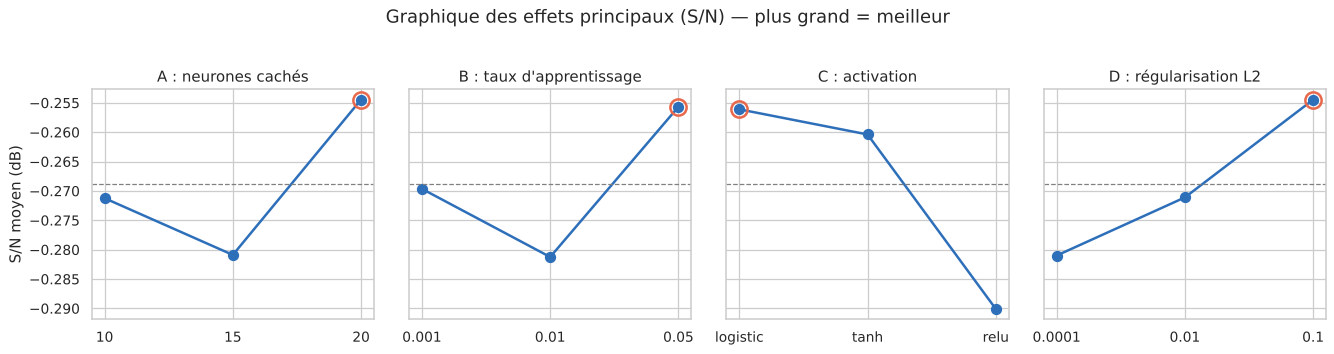

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
titles = ["A : neurones cachés", "B : taux d'apprentissage", "C : activation", "D : régularisation L2"]
grand = taguchi1["S/N (dB)"].mean()
for ax, f, t in zip(axes, factors, titles):
    vals = resp.loc[[f"Niveau {k}" for k in (1, 2, 3)], f].values
    ax.plot([str(v) for v in levels[f]], vals, "o-", lw=2, ms=8, color="#2E6FBA")
    ax.axhline(grand, ls="--", c="gray", lw=1)
    k = np.argmax(vals); ax.plot(k, vals[k], "o", ms=13, mfc="none", mec="#E8684C", mew=2)
    ax.set_title(t)
axes[0].set_ylabel("S/N moyen (dB)")
fig.suptitle("Graphique des effets principaux (S/N) — plus grand = meilleur", y=1.03)
plt.tight_layout(); plt.savefig("figures/04_effets_principaux_SN.png", bbox_inches="tight"); plt.show()

### 4.2 ANOVA sur le rapport S/N
L'ANOVA décompose la variabilité totale du S/N entre les facteurs et donne le **pourcentage de contribution** de chacun. Avec L9(3⁴), les 4 facteurs utilisent les 8 degrés de liberté : on regroupe (*pooling*) le facteur le moins influent dans l'erreur, comme le préconise Taguchi.

In [12]:
sn = taguchi1["S/N (dB)"].values
SS_T = np.sum((sn - sn.mean())**2)
anova = []
for f in factors:
    ss = sum(3 * (taguchi1.loc[taguchi1[f] == k, "S/N (dB)"].mean() - sn.mean())**2 for k in (1, 2, 3))
    anova.append({"Facteur": f, "ddl": 2, "SS": ss})
anova = pd.DataFrame(anova)
pooled = anova.loc[anova["SS"].idxmin(), "Facteur"]
SS_e, df_e = anova.loc[anova["Facteur"] == pooled, "SS"].values[0], 2
anova["MS"] = anova["SS"] / anova["ddl"]
anova["F"] = np.where(anova["Facteur"] == pooled, np.nan, anova["MS"] / (SS_e / df_e))
anova["Contribution (%)"] = 100 * anova["SS"] / SS_T
anova.loc[anova["Facteur"] == pooled, "Facteur"] = pooled + " (regroupé → erreur)"
anova.loc[len(anova)] = ["Total", 8, SS_T, np.nan, np.nan, 100.0]
anova.to_csv("results/taguchi_anova.csv", index=False)
anova.round(4)

,Facteur,ddl,SS,MS,F,Contribution (%)
0,A_neurones,2,0.0011,0.0005,1.0927,20.6976
1,B_lr (regroupé → erreur),2,0.0010,0.0005,NaN,18.9413
2,C_activation,2,0.0021,0.0010,2.0896,39.5804
3,D_alpha,2,0.0011,0.0005,1.0971,20.7807
4,Total,8,0.0052,NaN,NaN,100.0000


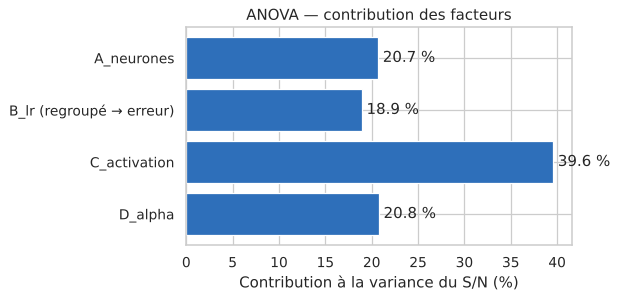

In [13]:
a = anova.iloc[:-1]
plt.figure(figsize=(7, 3.5))
plt.barh(a["Facteur"], a["Contribution (%)"], color="#2E6FBA")
for i, v in enumerate(a["Contribution (%)"]):
    plt.text(v + 0.5, i, f"{v:.1f} %", va="center")
plt.xlabel("Contribution à la variance du S/N (%)"); plt.title("ANOVA — contribution des facteurs")
plt.gca().invert_yaxis()
plt.tight_layout(); plt.savefig("figures/05_anova_contribution.png", bbox_inches="tight"); plt.show()

### 4.3 Expérience de confirmation
On prédit le S/N à la configuration optimale (modèle additif de Taguchi) puis on le **vérifie expérimentalement**. On compare aussi avec la configuration de départ de l'article (15 neurones, sigmoïde ; lr = 0,01 et alpha = 0,0001).

$$ \widehat{S/N}_{opt} = \overline{S/N} + \sum_{f}\left(\overline{S/N}_{f,\,opt} - \overline{S/N}\right) $$

In [14]:
pred_sn = grand + sum(resp.loc[f"Niveau {best_levels[f]}", f] - grand for f in factors)

ref_params = {"A_neurones": 15, "B_lr": 0.01, "C_activation": "logistic", "D_alpha": 1e-4}
best_run = taguchi1.loc[taguchi1["S/N (dB)"].idxmax()]
best_run_params = {f: levels[f][int(best_run[f]) - 1] for f in factors}
candidates = {"Optimum prédit (Taguchi)": best_params,
              f"Meilleur essai L9 (n°{int(best_run['essai'])})": best_run_params,
              "Référence (article)": ref_params}
conf_rows = []
for name, p in candidates.items():
    a = cv_accuracies(p)
    conf_rows.append({"Configuration": name, "Paramètres": str(p), "Acc. CV moy.": a.mean(),
                      "Écart-type": a.std(), "S/N observé (dB)": sn_larger_better(a)})
confirm = pd.DataFrame(conf_rows)
final_name = confirm.loc[confirm["S/N observé (dB)"].idxmax(), "Configuration"]
final_params = candidates[final_name]
confirm.to_csv("results/taguchi_confirmation.csv", index=False)
print(f"S/N prédit à l'optimum : {pred_sn:.3f} dB")
print(f"Configuration finale retenue : {final_name} -> {final_params}")
confirm.round(4)

S/N prédit à l'optimum : -0.214 dB
Configuration finale retenue : Meilleur essai L9 (n°8) -> {'A_neurones': 20, 'B_lr': 0.01, 'C_activation': 'logistic', 'D_alpha': 0.1}


,Configuration,Paramètres,Acc. CV moy.,Écart-type,S/N observé (dB)
0,Optimum prédit (Taguchi),"{'A_neurones': 20, 'B_lr': 0.05, 'C_activation...",0.9689,0.0137,-0.2768
1,Meilleur essai L9 (n°8),"{'A_neurones': 20, 'B_lr': 0.01, 'C_activation...",0.9731,0.0136,-0.2397
2,Référence (article),"{'A_neurones': 15, 'B_lr': 0.01, 'C_activation...",0.9710,0.0167,-0.2599


**Interprétation.** Les écarts de S/N entre niveaux (Delta < 0,04 dB, soit moins de 0,5 point d'accuracy) sont du même ordre que la dispersion due aux répétitions, et les rapports F de l'ANOVA restent faibles (F < 3 pour 2 et 2 ddl, alors que le seuil à 5 % est F = 19). Sur WDBC, presque toutes les configurations raisonnables donnent ~97 % : **les hyperparamètres testés ont peu d'influence**. Dans ce cas, l'optimum « additif » prédit par Taguchi n'est pas forcément confirmé ; on retient alors, parmi les candidats, la configuration au **S/N observé le plus élevé** (règle classique quand la confirmation échoue).

## 5. Méthode de Taguchi — Expérience 2 : partition des données
L'article compare 4 partitions entraînement/validation/test avec un plan L4. Nous évaluons ces 4 niveaux avec la configuration finale retenue, 15 répétitions chacune, et retenons la partition au S/N (accuracy de **validation**) le plus élevé.

In [15]:
splits = {"50/25/25": (.50, .25, .25), "60/20/20": (.60, .20, .20),
          "70/15/15": (.70, .15, .15), "80/10/10": (.80, .10, .10)}
rows = []
for name, (a_, b_, c_) in splits.items():
    accs = []
    for r in range(15):
        Xtr_, Xva_, _, ytr_, yva_, _ = split_data(X, y, a_, b_, c_, seed=200 + r)
        m = train_with(final_params, Xtr_, ytr_, Xva_, yva_, seed=200 + r)
        accs.append(accuracy_score(yva_, m.predict(Xva_)))
    rows.append({"Partition": name, "n_val": len(yva_), "Acc. val. moy.": np.mean(accs),
                 "Écart-type": np.std(accs), "S/N (dB)": sn_larger_better(accs)})
part = pd.DataFrame(rows)
best_split = part.loc[part["S/N (dB)"].idxmax(), "Partition"]
part.to_csv("results/taguchi_partitions.csv", index=False)
print("Partition retenue :", best_split)
part.round(4)

Partition retenue : 60/20/20


,Partition,n_val,Acc. val. moy.,Écart-type,S/N (dB)
0,50/25/25,142,0.9770,0.0094,-0.2034
1,60/20/20,114,0.9836,0.0090,-0.1445
2,70/15/15,85,0.9788,0.0123,-0.1880
3,80/10/10,57,0.9778,0.0186,-0.2000


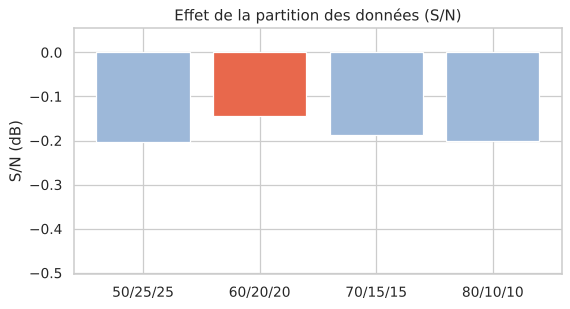

In [16]:
plt.figure(figsize=(6.5, 3.6))
plt.bar(part["Partition"], part["S/N (dB)"], color=["#E8684C" if p == best_split else "#9DB8D9" for p in part["Partition"]])
plt.ylim(part["S/N (dB)"].min() - 0.3, part["S/N (dB)"].max() + 0.2)
plt.ylabel("S/N (dB)"); plt.title("Effet de la partition des données (S/N)")
plt.tight_layout(); plt.savefig("figures/06_partitions_SN.png", bbox_inches="tight"); plt.show()

> **Remarque :** avec de petites validations (80/10/10 → 57 observations), l'accuracy varie par pas de ~1,8 point, ce qui rend la comparaison bruitée. Ici 60/20/20 et 70/15/15 sont quasi à égalité ; dans la suite nous utilisons **70/15/15**, retenue par l'article, pour rester comparable.

## 6. Évaluation finale du modèle ANN-Taguchi
### 6.1 Trente exécutions aléatoires (70/15/15)
Comme dans l'article, on répète 30 fois (nouvelle partition + nouvelle initialisation) et on rapporte la moyenne et l'écart-type sur l'ensemble de **test**.

In [17]:
res30, cms = [], np.zeros((2, 2), int)
for r in range(30):
    Xtr_, Xva_, Xte_, ytr_, yva_, yte_ = split_data(X, y, .70, .15, .15, seed=1000 + r)
    m = train_with(final_params, Xtr_, ytr_, Xva_, yva_, seed=1000 + r)
    res30.append({"run": r + 1, "train_acc": accuracy_score(ytr_, m.predict(Xtr_)),
                  "val_acc": accuracy_score(yva_, m.predict(Xva_)),
                  **{"test_" + k: v for k, v in metrics(m, Xte_, yte_).items()}})
    cms += confusion_matrix(yte_, m.predict(Xte_), labels=[0, 1])
res30 = pd.DataFrame(res30)
res30.to_csv("results/30_executions.csv", index=False)
summary30 = res30.drop(columns="run").agg(["mean", "std", "min", "max"]).T
summary30.round(4)

,mean,std,min,max
train_acc,0.9882,0.0032,0.9824,0.9925
val_acc,0.9761,0.0133,0.9529,1.0000
test_accuracy,0.9744,0.0163,0.9419,1.0000
test_sensitivity,0.9531,0.0365,0.8750,1.0000
test_specificity,0.9870,0.0147,0.9630,1.0000
test_precision,0.9782,0.0244,0.9375,1.0000
test_f1,0.9650,0.0225,0.9180,1.0000
test_auc,0.9949,0.0058,0.9769,1.0000


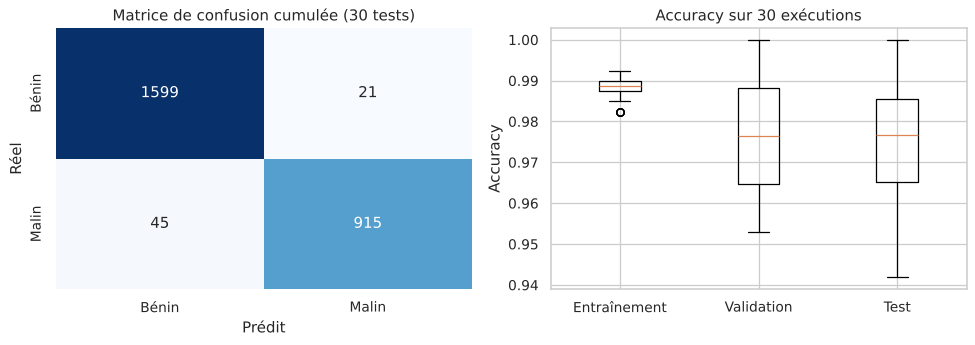

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(cms, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["Bénin", "Malin"], yticklabels=["Bénin", "Malin"])
ax[0].set_xlabel("Prédit"); ax[0].set_ylabel("Réel")
ax[0].set_title("Matrice de confusion cumulée (30 tests)")
ax[1].boxplot([res30["train_acc"], res30["val_acc"], res30["test_accuracy"]])
ax[1].set_xticks([1, 2, 3]); ax[1].set_xticklabels(["Entraînement", "Validation", "Test"])
ax[1].set_title("Accuracy sur 30 exécutions"); ax[1].set_ylabel("Accuracy")
plt.tight_layout(); plt.savefig("figures/07_confusion_30runs.png", bbox_inches="tight"); plt.show()

### 6.2 Modèle final unique : rapport de classification et courbe ROC

              precision    recall  f1-score   support

       Bénin     0.9818    1.0000    0.9908        54
       Malin     1.0000    0.9688    0.9841        32

    accuracy                         0.9884        86
   macro avg     0.9909    0.9844    0.9875        86
weighted avg     0.9886    0.9884    0.9883        86



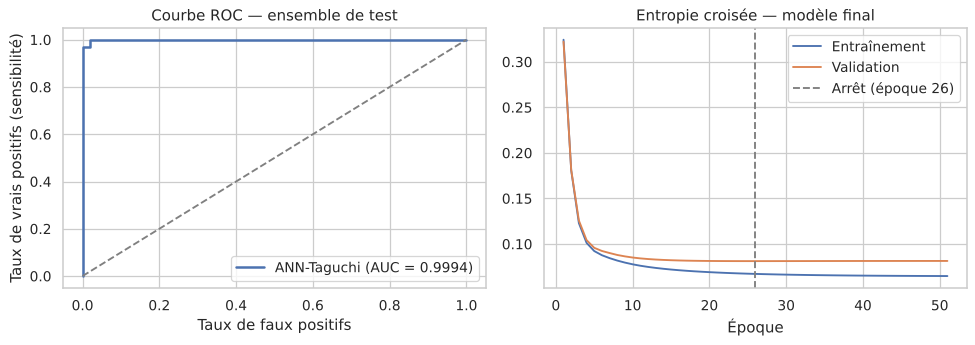

In [19]:
final_model, final_hist = train_with(final_params, X_tr, y_tr, X_va, y_va, return_history=True)
print(classification_report(y_te, final_model.predict(X_te), target_names=["Bénin", "Malin"], digits=4))
fpr, tpr, _ = roc_curve(y_te, final_model.predict_proba(X_te)[:, 1])
auc = roc_auc_score(y_te, final_model.predict_proba(X_te)[:, 1])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(fpr, tpr, lw=2, label=f"ANN-Taguchi (AUC = {auc:.4f})"); ax[0].plot([0, 1], [0, 1], "--", c="gray")
ax[0].set_xlabel("Taux de faux positifs"); ax[0].set_ylabel("Taux de vrais positifs (sensibilité)")
ax[0].set_title("Courbe ROC — ensemble de test"); ax[0].legend(loc="lower right")
ep = np.arange(1, len(final_hist["val_loss"]) + 1)
ax[1].plot(ep, final_hist["train_loss"], label="Entraînement"); ax[1].plot(ep, final_hist["val_loss"], label="Validation")
ax[1].axvline(final_model.best_epoch_, ls="--", c="gray", label=f"Arrêt (époque {final_model.best_epoch_})")
ax[1].set_title("Entropie croisée — modèle final"); ax[1].set_xlabel("Époque"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/08_roc_modele_final.png", bbox_inches="tight"); plt.show()

### 6.3 Validation croisée stratifiée 10-fold

In [20]:
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
cv_rows = []
for k, (tr_idx, te_idx) in enumerate(skf.split(X, y), start=1):
    # 15 % de la partie entraînement sert de validation pour l'arrêt précoce
    Xtr_, Xva_, ytr_, yva_ = train_test_split(X[tr_idx], y[tr_idx], test_size=.15, stratify=y[tr_idx], random_state=k)
    sc = StandardScaler().fit(Xtr_)
    m = train_with(final_params, sc.transform(Xtr_), ytr_, sc.transform(Xva_), yva_, seed=k)
    cv_rows.append({"fold": k, **metrics(m, sc.transform(X[te_idx]), y[te_idx])})
cv = pd.DataFrame(cv_rows)
cv.loc["Moyenne"] = cv.mean(numeric_only=True); cv.loc["Écart-type"] = cv.iloc[:10].std(numeric_only=True)
cv.loc[["Moyenne", "Écart-type"], "fold"] = np.nan
cv.to_csv("results/validation_croisee_10fold.csv")
cv.round(4)

,fold,accuracy,sensitivity,specificity,precision,f1,auc
0,1.0,0.9474,0.9545,0.9429,0.9130,0.9333,0.9961
1,2.0,0.9825,1.0000,0.9714,0.9565,0.9778,0.9987
2,3.0,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
3,4.0,0.9474,0.8571,1.0000,1.0000,0.9231,0.9947
4,5.0,0.9825,0.9524,1.0000,1.0000,0.9756,0.9788
5,6.0,0.9474,0.8571,1.0000,1.0000,0.9231,0.9894
6,7.0,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
7,8.0,0.9825,1.0000,0.9722,0.9545,0.9767,1.0000
8,9.0,0.9825,0.9524,1.0000,1.0000,0.9756,0.9960
9,10.0,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


## 7. Comparaison avec d'autres classifieurs
Mêmes 30 partitions **85 % / 15 %** (entraînement / test) pour tous les modèles, normalisation ajustée sur l'entraînement. Pour l'ANN-Taguchi, 15 % de la partie entraînement servent à l'arrêt précoce : chaque modèle dispose donc des mêmes données.

In [21]:
models = {
    "Régression logistique": LogisticRegression(max_iter=5000),
    "SVM linéaire": SVC(kernel="linear", probability=True),
    "SVM RBF": SVC(kernel="rbf", probability=True),
    "k-NN (k=5)": KNeighborsClassifier(5),
    "Arbre de décision": DecisionTreeClassifier(random_state=SEED),
    "Forêt aléatoire": RandomForestClassifier(300, random_state=SEED),
    "Naive Bayes": GaussianNB(),
    "ANN par défaut (100 neurones, sklearn)": MLPClassifier(max_iter=1000, random_state=SEED),
}
comp = {name: [] for name in models}
for r in range(30):
    Xtr_, Xte_, ytr_, yte_ = train_test_split(X, y, test_size=.15, stratify=y, random_state=1000 + r)
    for name, mdl in models.items():
        pipe = make_pipeline(StandardScaler(), mdl).fit(Xtr_, ytr_)
        comp[name].append(accuracy_score(yte_, pipe.predict(Xte_)))
    # ANN-Taguchi : même ensemble d'entraînement (85 %), dont 15 % réservés à l'arrêt précoce
    Xa, Xs, ya, ys = train_test_split(Xtr_, ytr_, test_size=.15, stratify=ytr_, random_state=r)
    sc = StandardScaler().fit(Xa)
    m = train_with(final_params, sc.transform(Xa), ya, sc.transform(Xs), ys, seed=r)
    comp.setdefault("ANN-Taguchi (ce projet)", []).append(accuracy_score(yte_, m.predict(sc.transform(Xte_))))
comp_df = pd.DataFrame({"Accuracy test moy.": {k: np.mean(v) for k, v in comp.items()},
                        "Écart-type": {k: np.std(v) for k, v in comp.items()}}).sort_values("Accuracy test moy.", ascending=False)
comp_df.to_csv("results/comparaison_classifieurs.csv")
comp_df.round(4)

,Accuracy test moy.,Écart-type
ANN-Taguchi (ce projet),0.9787,0.0113
Régression logistique,0.9775,0.0144
"ANN par défaut (100 neurones, sklearn)",0.9760,0.0124
SVM RBF,0.9752,0.0149
SVM linéaire,0.9713,0.0137
k-NN (k=5),0.9659,0.0144
Forêt aléatoire,0.9636,0.0212
Naive Bayes,0.9337,0.0279
Arbre de décision,0.9329,0.0304


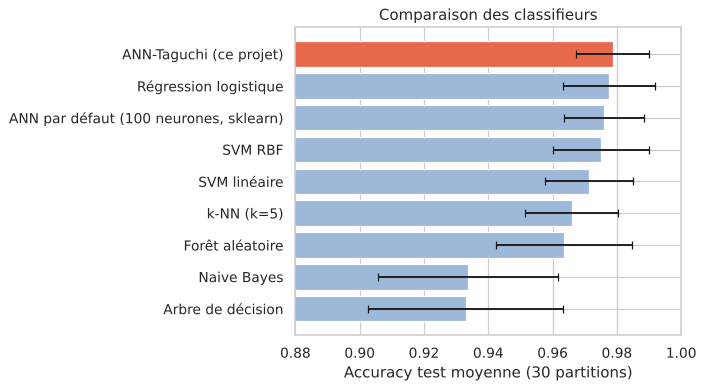

In [22]:
plt.figure(figsize=(8, 4.5))
colors = ["#E8684C" if "Taguchi" in n else "#9DB8D9" for n in comp_df.index]
plt.barh(comp_df.index, comp_df["Accuracy test moy."], xerr=comp_df["Écart-type"], color=colors, capsize=3)
plt.xlim(0.88, 1.0); plt.gca().invert_yaxis()
plt.xlabel("Accuracy test moyenne (30 partitions)"); plt.title("Comparaison des classifieurs")
plt.tight_layout(); plt.savefig("figures/09_comparaison_classifieurs.png", bbox_inches="tight"); plt.show()

In [23]:
s = summary30["mean"]
article = pd.DataFrame({
    "Article (2021)": [0.988, 0.991, 0.984, 0.988, 0.987],
    "Ce projet": [s["test_accuracy"], s["test_sensitivity"], s["test_specificity"], s["test_f1"],
                  cv.loc["Moyenne", "accuracy"]]},
    index=["Accuracy test (30 runs)", "Sensibilité", "Spécificité", "F-score", "Accuracy 10-fold CV"])
article.to_csv("results/comparaison_article.csv")
article.round(4)

,Article (2021),Ce projet
Accuracy test (30 runs),0.988,0.9744
Sensibilité,0.991,0.9531
Spécificité,0.984,0.9870
F-score,0.988,0.9650
Accuracy 10-fold CV,0.987,0.9772


## 8. Conclusion
*(Valeurs obtenues lors de notre exécution ; elles peuvent varier légèrement selon la version de scikit-learn.)*

**Configuration finale :** 20 neurones cachés, activation sigmoïde (logistic), taux d'apprentissage 0,01, régularisation L2 alpha = 0,1 (essai n°8 du plan L9, confirmé comme meilleur S/N observé).

| Indicateur | Article (2021) | Ce projet |
|---|---|---|
| Accuracy test, 30 exécutions (70/15/15) | 98,8 % | 97,4 % ± 1,6 |
| Sensibilité / Spécificité | 99,1 % / 98,4 % | 95,3 % / 98,7 % |
| F-score | 98,8 % | 96,5 % |
| Accuracy validation croisée 10-fold | 98,7 % | 97,7 % ± 2,2 |
| AUC (30 exécutions) | — | 0,995 |

1. **La méthode de Taguchi** a permis d'étudier 4 facteurs à 3 niveaux avec 9 essais au lieu de 81, en mesurant la robustesse par le rapport S/N. Son enseignement principal ici : sur WDBC, les hyperparamètres testés ont **peu d'influence** (toutes les configurations donnent 96-97 % en validation croisée, effets non significatifs à l'ANOVA). L'activation est le facteur le plus influent (la sigmoïde est la plus robuste, relu la moins robuste) ; une régularisation forte (alpha = 0,1) et 20 neurones sont légèrement favorables.
2. **L'optimum additif prédit n'a pas été confirmé** (S/N observé < S/N prédit), signe que les effets sont dans le bruit ou que des interactions existent ; nous avons retenu le meilleur essai observé, comme le prévoit la démarche Taguchi.
3. **Partitions :** 60/20/20 obtient le meilleur S/N dans notre expérience, 70/15/15 (choix de l'article) est très proche ; l'écart est dans le bruit.
4. **Comparaison équitable** (mêmes 30 partitions 85/15) : l'ANN-Taguchi obtient la meilleure accuracy moyenne (97,9 %) et la plus faible dispersion, devant la régression logistique (97,8 %) et les SVM (97,1-97,5 %). Les écarts entre les meilleurs modèles restent inférieurs à un écart-type.
5. **Écart avec l'article (~1 point) :** dans l'article, le nombre de neurones et la partition sont choisis sur des partitions proches de celles de l'évaluation, ce qui peut gonfler le résultat, et le « filtrage du bruit » appliqué aux données n'est pas décrit. Ici, l'ensemble de test n'est jamais utilisé pour le réglage.
6. **Point d'attention médical :** la sensibilité (95 %) est plus faible que la spécificité (99 %) : le modèle rate plus de tumeurs malignes qu'il ne produit de fausses alertes. Abaisser le seuil de décision (par ex. 0,3 au lieu de 0,5) augmenterait la sensibilité.

**Pistes d'amélioration :** plan L18/L27 pour estimer les interactions, sélection de variables (forte colinéarité radius/perimeter/area), ajustement du seuil de décision, ensemble de plusieurs ANN.